# RiskLens: Fairness check (gender and age)

**Why I'm doing this:** the SHAP notebook showed that gender is the 6th most important feature of my model, and that age is in the model twice (`DAYS_BIRTH` and my own `AGE` column). In lending these are sensitive attributes, so I want to check two things: does the model treat groups differently, and what happens if I take these columns out?

**What I'll do**
1. Load the model and calibrator from notebook 08
2. Build the groups (gender, age group)
3. Flag the riskiest 20% of applicants
4. Compare the groups
5. Retrain the model without gender and age
6. Compare the two models
7. Check if other columns still reveal gender
8. One figure for the README

**The metrics, in plain words**
- **Flagged:** the share of the group that the model marks as risky
- **Recall:** of the people who really default, how many get flagged
- **False positive rate:** of the people who would have repaid, how many get flagged anyway (this is the "unfair rejection" rate)
- **Precision:** of the people flagged, how many really default
- **Avg predicted vs real default rate:** is the model's probability right *inside* the group?

**About the threshold:** in notebook 08 I found that the 0.5 threshold doesn't make sense on calibrated probabilities. So here I flag the **riskiest 20%** of applicants, with the same cutoff for everyone. That's my own simple choice for this analysis, not a real lending policy.

**Upfront caveats:** I only look at gender (F/M) and age groups, with one random split and no confidence intervals. This analysis doesn't prove that the model is fair or unfair. It just shows where the differences are.

## 1. Setup

In [2]:
# Step 1: Setup (reuses your saved model and calibrator)

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

df = pd.read_csv("../data/processed/train_merged.csv")
y = df["TARGET"]
X = df.drop(columns=["TARGET", "SK_ID_CURR"])
X = X.replace([np.inf, -np.inf], np.nan)

cat_cols = X.select_dtypes(exclude="number").columns
for c in cat_cols:
    X[c] = X[c].astype("category")

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# same calibration / test halves as notebook 08
idx_cal, idx_test = train_test_split(
    np.arange(len(y_val)), test_size=0.5, stratify=y_val, random_state=42
)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

model = joblib.load("../models/lgbm_model.joblib")
platt = joblib.load("../models/platt_calibrator.joblib")

raw = model.predict_proba(X_val)[:, 1]
prob = platt.predict_proba(logit(raw).reshape(-1, 1))[:, 1]

# I only evaluate on the test half, which the calibrator never saw
X_test = X_val.iloc[idx_test]
y_test = y_val.iloc[idx_test].values
p_test = prob[idx_test]

print(roc_auc_score(y_test, p_test))   # should be about 0.7657
print(p_test.mean(), y_test.mean())    # about 0.080 and 0.0807

0.7657381738501068
0.08013006038668513 0.08074271592091571


The AUC is **0.7657** and the average predicted probability is **0.080** against a real default rate of **0.0807**, the same as in notebook 08, so the model and the calibrator are the right ones. I only evaluate on the **test half (30,752 rows)**, because the calibrator was fitted on the other half.

## 2. The groups

In [3]:
# Step 2: Build the groups

groups = pd.DataFrame({
    "gender": X_test["CODE_GENDER"].astype(str).values,
    "age_group": pd.cut(-X_test["DAYS_BIRTH"] / 365, bins=[20, 30, 40, 50, 60, 70]).astype(str).values,
    "y": y_test,
    "p": p_test,
})

print(groups["gender"].value_counts())
print(groups["age_group"].value_counts().sort_index())

gender
F    20345
M    10407
Name: count, dtype: int64
age_group
(20, 30]    4366
(30, 40]    8250
(40, 50]    7662
(50, 60]    6807
(60, 70]    3667
Name: count, dtype: int64


| Gender | Applicants |
|---|---|
| F | 20,345 |
| M | 10,407 |

| Age group | Applicants |
|---|---|
| 20-30 | 4,366 |
| 30-40 | 8,250 |
| 40-50 | 7,662 |
| 50-60 | 6,807 |
| 60-70 | 3,667 |

The third gender category in the data (`XNA`, unknown) doesn't appear in the test half, so I only compare women and men. Age comes from `DAYS_BIRTH` converted to years. The 60-70 group is the smallest, so its numbers are less reliable than the others.

## 3. Flagging the riskiest 20%

In [4]:
# Step 3: Flag the riskiest 20%

threshold = np.quantile(p_test, 0.80)
print("threshold (calibrated probability):", round(threshold, 4))

groups["flag"] = (groups["p"] >= threshold).astype(int)
print("share flagged:", groups["flag"].mean())

threshold (calibrated probability): 0.1257
share flagged: 0.20001951092611864


The cutoff is a calibrated default probability of **12.6%**: everyone at or above it gets flagged. By construction that flags exactly 20.0% of the test applicants. From notebook 08, the riskiest 20% hold about 55% of all the defaults, so this is a reasonable "flag the risky ones" rule.

## 4. Comparing the groups (model with gender and age)

In [6]:
# Step 4: Metrics for each group

def group_table(data, col):
    rows = []
    for name, g in data.groupby(col):
        if len(g) < 200:
            continue
        tn, fp, fn, tp = confusion_matrix(g["y"], g["flag"], labels=[0, 1]).ravel()
        rows.append({
            col: name,
            "n": len(g),
            "real default rate": g["y"].mean(),
            "avg predicted": g["p"].mean(),
            "flagged": g["flag"].mean(),
            "recall": tp / (tp + fn),
            "false positive rate": fp / (fp + tn),
            "precision": tp / (tp + fp),
            "AUC": roc_auc_score(g["y"], g["p"]),
        })
    return pd.DataFrame(rows).round(3)

print(group_table(groups, "gender"))
print(group_table(groups, "age_group"))

  gender      n  real default rate  avg predicted  flagged  recall  \
0      F  20345              0.070          0.071    0.160   0.483   
1      M  10407              0.102          0.099    0.279   0.628   

   false positive rate  precision    AUC  
0                0.135      0.212  0.758  
1                0.240      0.229  0.765  
  age_group     n  real default rate  avg predicted  flagged  recall  \
0  (20, 30]  4366              0.113          0.118    0.367   0.660   
1  (30, 40]  8250              0.098          0.092    0.251   0.612   
2  (40, 50]  7662              0.075          0.076    0.179   0.527   
3  (50, 60]  6807              0.066          0.062    0.127   0.423   
4  (60, 70]  3667              0.044          0.049    0.067   0.262   

   false positive rate  precision    AUC  
0                0.329      0.204  0.725  
1                0.211      0.240  0.773  
2                0.151      0.219  0.763  
3                0.106      0.219  0.757  
4           

| Gender | n | Real default rate | Avg predicted | Flagged | Recall | False positive rate | Precision | AUC |
|---|---|---|---|---|---|---|---|---|
| F | 20,345 | 7.0% | 7.1% | 16.0% | 48.3% | 13.5% | 21.2% | 0.758 |
| M | 10,407 | 10.2% | 9.9% | 27.9% | 62.8% | 24.0% | 22.9% | 0.765 |

| Age group | n | Real default rate | Avg predicted | Flagged | Recall | False positive rate | Precision | AUC |
|---|---|---|---|---|---|---|---|---|
| 20-30 | 4,366 | 11.3% | 11.8% | 36.7% | 66.0% | 32.9% | 20.4% | 0.725 |
| 30-40 | 8,250 | 9.8% | 9.2% | 25.1% | 61.2% | 21.1% | 24.0% | 0.773 |
| 40-50 | 7,662 | 7.5% | 7.6% | 17.9% | 52.7% | 15.1% | 21.9% | 0.763 |
| 50-60 | 6,807 | 6.6% | 6.2% | 12.7% | 42.3% | 10.6% | 21.9% | 0.757 |
| 60-70 | 3,667 | 4.4% | 4.9% | 6.7% | 26.2% | 5.8% | 17.1% | 0.715 |

- **The groups really are different in the data.** Men default more than women (10.2% vs 7.0%, about 1.5 times), and younger applicants default more than older ones (11.3% for 20-30 vs 4.4% for 60-70, about 2.6 times). So some difference in what the model does is expected.
- **The probabilities fit inside each group.** The average predicted probability is within about 0.6 points of the real default rate for every group. So the model isn't systematically too pessimistic or too optimistic about one group.
- **The cutoff makes the differences much bigger.** Men are flagged 1.7 times as often as women (27.9% vs 16.0%), and the youngest group is flagged 5.5 times as often as the oldest (36.7% vs 6.7%), compared to default-rate differences of 1.5 and 2.6 times. Flagging the top 20% picks the extremes of the distribution, so a modest difference in average risk turns into a big difference in who gets flagged.
- **False positive rate:** among people who would have repaid, 24.0% of men get flagged against 13.5% of women, and 32.9% of the 20-30 group against 5.8% of the 60-70 group. A young person who would repay is about 5-6 times more likely to be flagged by mistake than an older one. This is the number that worries me most.
- **Recall** is higher for men (62.8% vs 48.3%) and for younger people (66.0% vs 26.2%), but that's mostly because more of them get flagged.
- **Precision** is similar across groups (about 17-24%), so a flag means roughly a 1 in 5 chance of a real default whoever you are. The 60-70 group is the lowest (17.1%), but it's also the smallest, with only about 250 people flagged.
- **AUC** is about the same for women and men (0.758 vs 0.765), but lower for the youngest (0.725) and the oldest (0.715) than for the middle groups (0.757-0.773). The model separates defaulters from repayers less well for those two groups.

I can't make all of these numbers equal at the same time. When the real default rates differ between groups, it's known that you can't equalise the flag rate, the false positive rate and the calibration together. So the table shows *what* the differences are, and it's a judgement call which ones are acceptable.

## 5. Retraining without gender and age

I removed `CODE_GENDER`, `DAYS_BIRTH` and `AGE`. Age has to be removed twice because both columns have the same information. Everything else is the same as in notebook 06 (same split, same settings, same early stopping), so the only change is these three columns.

In [7]:
# Step 5: Retrain without gender and age

drop_cols = ["CODE_GENDER", "DAYS_BIRTH", "AGE"]
X_train_ns = X_train.drop(columns=drop_cols)
X_val_ns = X_val.drop(columns=drop_cols)

# same early-stopping split as notebook 06
X_tr, X_es, y_tr, y_es = train_test_split(
    X_train_ns, y_train, test_size=0.1, stratify=y_train, random_state=42
)

model_ns = LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_ns.fit(
    X_tr, y_tr,
    eval_set=[(X_es, y_es)],
    eval_metric="auc",
    callbacks=[early_stopping(100), log_evaluation(100)]
)
print("best number of trees:", model_ns.best_iteration_)

c:\Users\HP\Desktop\Projects\risklens-explainable-credit-risk\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 17874, number of negative: 203533
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.129331 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12944
[LightGBM] [Info] Number of data points in the train set: 221407, number of used features: 125
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.752969	valid_0's binary_logloss: 0.576562
[200]	valid_0's auc: 0.755966	valid_0's binary_logloss: 0.5603
[300]	valid_0's auc: 0.756168	valid_0's binary_logloss: 0.548247
[400]	valid_0's auc: 0.755307	valid_0's binary_logloss: 0.537618
Early stopping, best iteration is:
[343]	valid_0's auc: 0.756532	valid_0's binary_logloss: 0.543335
best number of tre

The new model stopped at **343 trees** (the original stopped at 167) and uses 125 features. The AUC on the early-stopping set is 0.7565, a bit below the 0.7583 of the original. The LightGBM warning in the output is about a future version and doesn't change anything.

Its raw scores have a different scale, so it needs its own calibrator, which I fit on the calibration half like in notebook 08.

## 6. Comparing the two models

In [8]:
# Step 6: Calibrate the new model and compare

raw_ns = model_ns.predict_proba(X_val_ns)[:, 1]

platt_ns = LogisticRegression(C=1e6, max_iter=1000)
platt_ns.fit(logit(raw_ns[idx_cal]).reshape(-1, 1), y_val.iloc[idx_cal].values)
p_test_ns = platt_ns.predict_proba(logit(raw_ns[idx_test]).reshape(-1, 1))[:, 1]

for name, p in [("with gender and age", p_test), ("without gender and age", p_test_ns)]:
    print(name, "| AUC:", round(roc_auc_score(y_test, p), 4),
          "| Brier:", round(brier_score_loss(y_test, p), 4))

with gender and age | AUC: 0.7657 | Brier: 0.0671
without gender and age | AUC: 0.7647 | Brier: 0.0673


In [9]:
groups_ns = groups[["gender", "age_group", "y"]].copy()
groups_ns["p"] = p_test_ns
groups_ns["flag"] = (p_test_ns >= np.quantile(p_test_ns, 0.80)).astype(int)

print(group_table(groups_ns, "gender"))
print(group_table(groups_ns, "age_group"))

  gender      n  real default rate  avg predicted  flagged  recall  \
0      F  20345              0.070          0.074    0.170   0.498   
1      M  10407              0.102          0.093    0.258   0.603   

   false positive rate  precision    AUC  
0                0.146      0.204  0.757  
1                0.219      0.238  0.766  
  age_group     n  real default rate  avg predicted  flagged  recall  \
0  (20, 30]  4366              0.113          0.122    0.385   0.682   
1  (30, 40]  8250              0.098          0.089    0.238   0.600   
2  (40, 50]  7662              0.075          0.074    0.173   0.515   
3  (50, 60]  6807              0.066          0.065    0.135   0.423   
4  (60, 70]  3667              0.044          0.050    0.072   0.250   

   false positive rate  precision    AUC  
0                0.348      0.200  0.725  
1                0.199      0.248  0.776  
2                0.145      0.222  0.763  
3                0.115      0.206  0.747  
4           

| Model | ROC AUC | Brier |
|---|---|---|
| With gender and age | 0.7657 | 0.0671 |
| Without gender and age | 0.7647 | 0.0673 |

**The cost of removing them is tiny:** the AUC goes down by 0.001 and the Brier score up by 0.0002. That's so small that I wouldn't claim it's a real loss.

Share flagged and false positive rate for each group (the full tables are in the output above):

| Group | Flagged (with) | Flagged (without) | False positive rate (with) | False positive rate (without) |
|---|---|---|---|---|
| F | 16.0% | 17.0% | 13.5% | 14.6% |
| M | 27.9% | 25.8% | 24.0% | 21.9% |
| 20-30 | 36.7% | 38.5% | 32.9% | 34.8% |
| 30-40 | 25.1% | 23.8% | 21.1% | 19.9% |
| 40-50 | 17.9% | 17.3% | 15.1% | 14.5% |
| 50-60 | 12.7% | 13.5% | 10.6% | 11.5% |
| 60-70 | 6.7% | 7.2% | 5.8% | 6.4% |

| Gap | With gender and age | Without |
|---|---|---|
| Flagged, men vs women | 27.9% vs 16.0% (1.74x) | 25.8% vs 17.0% (1.52x) |
| False positive rate, men vs women | 24.0% vs 13.5% (1.78x) | 21.9% vs 14.6% (1.50x) |
| Flagged, 20-30 vs 60-70 | 36.7% vs 6.7% (5.5x) | 38.5% vs 7.2% (5.3x) |
| False positive rate, 20-30 vs 60-70 | 32.9% vs 5.8% (5.7x) | 34.8% vs 6.4% (5.4x) |

- **Gender:** taking out gender narrowed the gaps, by about a quarter to a third. Men are still flagged more often, though, and the real default rate is higher for men, so it's not surprising that some gap remains.
- **Age:** the gaps **barely changed**, and the youngest group is even flagged slightly more (38.5%). So removing `DAYS_BIRTH` and `AGE` didn't stop the model from treating young and old applicants very differently. My guess is that other columns carry age information (for example `DAYS_EMPLOYED`, since people who have worked for a long time are older), but I didn't test that.
- **Probabilities inside groups got slightly worse** without the sensitive columns. For example, the model now predicts 9.3% for men against a real 10.2% (before: 9.9%), and 12.2% for the 20-30 group against a real 11.3% (before: 11.8%).

## 7. Do other columns still reveal gender?

Removing a column doesn't remove its information if other columns carry it. So I trained a small model to predict gender from the remaining features. An AUC of 0.5 would mean nothing about gender is left.

In [10]:
# Step 7: Do other columns act as a stand-in for gender?

mask_tr = X_train["CODE_GENDER"].isin(["F", "M"]).values
mask_va = X_val["CODE_GENDER"].isin(["F", "M"]).values
g_tr = (X_train.loc[mask_tr, "CODE_GENDER"] == "M").astype(int)
g_va = (X_val.loc[mask_va, "CODE_GENDER"] == "M").astype(int)

proxy = LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=42, n_jobs=-1)
proxy.fit(X_train_ns.loc[mask_tr], g_tr)
print("AUC predicting gender:", roc_auc_score(g_va, proxy.predict_proba(X_val_ns.loc[mask_va])[:, 1]))

[LightGBM] [Info] Number of positive: 84119, number of negative: 161887
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.110216 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 12951
[LightGBM] [Info] Number of data points in the train set: 246006, number of used features: 125
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.341939 -> initscore=-0.654666
[LightGBM] [Info] Start training from score -0.654666
AUC predicting gender: 0.8990113608879967


The AUC for predicting gender from the other 125 columns is **0.899**. That's very high: the remaining columns still reveal gender almost as well as a good model can. So **taking out `CODE_GENDER` doesn't make the model blind to gender**, it only means the model doesn't use that column directly. I haven't checked which columns carry this information.

This also explains why the gender gaps only got smaller and didn't disappear.

In [ ]:
# It's to see which columns still reveal gender
pi = pd.Series(
    proxy.booster_.feature_importance(importance_type="gain"),
    index=X_train_ns.columns
).sort_values(ascending=False)
print(pi.head(10))

OCCUPATION_TYPE       692582.703183
OWN_CAR_AGE           173348.341535
ORGANIZATION_TYPE     141895.159655
EXT_SOURCE_1           90706.364721
AMT_INCOME_TOTAL       51277.121397
NAME_FAMILY_STATUS     50770.506613
FLAG_DOCUMENT_8        47033.888507
FLAG_OWN_CAR           26918.159666
DAYS_ID_PUBLISH        18715.498508
bureau_count           16726.340243
dtype: float64


## 8. Figure for the README

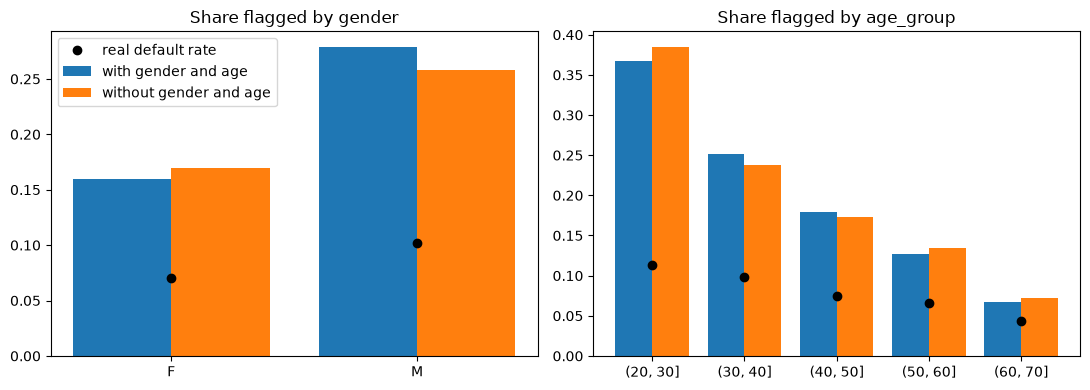

In [11]:
# Step 8: One figure for the README

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["gender", "age_group"]):
    a = group_table(groups, col).set_index(col)
    b = group_table(groups_ns, col).set_index(col)
    x = np.arange(len(a))
    ax.bar(x - 0.2, a["flagged"], width=0.4, label="with gender and age")
    ax.bar(x + 0.2, b["flagged"], width=0.4, label="without gender and age")
    ax.plot(x, a["real default rate"], "ko", label="real default rate")
    ax.set_xticks(x)
    ax.set_xticklabels(a.index)
    ax.set_title("Share flagged by " + col)
axes[0].legend()
plt.tight_layout()
plt.savefig("../reports/figures/fairness_flag_rates.png", dpi=150, bbox_inches="tight")
plt.show()

The bars show the share of each group that gets flagged (blue = model with gender and age, orange = model without), and the black dots show the real default rate of each group.

- The bars are higher than the dots because I flag 20% of all applicants while only about 8% default. What matters is the *shape*.
- By gender, the bar for men is much higher than for women, and removing gender makes it a bit shorter for men and a bit taller for women.
- By age, the bars fall much faster than the dots (the real default rate drops about 2.6 times from youngest to oldest, the flagged share drops about 5.5 times). Blue and orange are almost the same height in every age group.

In [13]:
import joblib
joblib.dump(model_ns, "../models/lgbm_model_nosens.joblib")
joblib.dump(platt_ns, "../models/platt_calibrator_nosens.joblib")

['../models/platt_calibrator_nosens.joblib']

## What I'm going to do

**I'll use the model without gender and age as my final model.** The reasons:
- it costs almost nothing (AUC 0.7657 → 0.7647, Brier 0.0671 → 0.0673)
- it narrows the gap between men and women by about a quarter to a third
- the model doesn't directly use two sensitive attributes anymore. In many countries, including in the EU, using gender in credit decisions is restricted or not allowed

**What this doesn't mean:** it doesn't mean the model is fair. Other columns still carry gender (AUC 0.899) and probably age, and young applicants who would repay still get flagged much more often than older ones. I'll say this clearly in the model card.

**Still to do:** save this model and its calibrator, choose a final threshold, and write the model card.

## Summary

**What I found**
- Men and younger applicants really do default more in this data (10.2% vs 7.0%, and 11.3% for 20-30 vs 4.4% for 60-70)
- The model's probabilities are accurate inside each group, but flagging the top 20% makes the gaps much bigger: young applicants who would repay are flagged about 5-6 times more than older ones, and men about 1.8 times more than women
- Removing gender and age costs almost nothing (AUC -0.001), narrows the gender gaps by about a quarter to a third, and doesn't change the age gaps
- The other columns still predict gender with an AUC of 0.899, so the model isn't blind to it

**Limits**
- One random split, no confidence intervals, and the 60-70 group is small
- A single threshold (top 20%) that I chose myself. A different threshold would give different gaps
- Only gender and age. Other personal columns in the model, such as family status and education, were not checked
- This is not a legal assessment

**Next:** choose the final threshold, write the model card, then the API